# Project:Electricity Usage During Load Shedding Analyze household electricity usage before, during, and after.

In [3]:
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.formula.api import ols
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.multicomp import pairwise_tukeyhsd

# 1. LOAD DATA

In [4]:
with open('load_shedding_7500_rows.json', 'r') as file:
    data = json.load(file)

df = pd.DataFrame(data)

print("="*60)
print("1. DATA OVERVIEW")
print("="*60)
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
print("\nFirst 3 rows:")
print(df.head(3))
print("\nMissing values:", df.isnull().sum().sum())
print(df.describe())
print("\n" + "="*60)

1. DATA OVERVIEW
Rows: 7500, Columns: 11

First 3 rows:
   Household_ID   Area_Type  Family_Size Income_Level  Appliance_Count  \
0             1  Semi-Urban            3       Middle               15   
1             1  Semi-Urban            3       Middle               15   
2             1  Semi-Urban            3       Middle               15   

  Backup_Type Load_Shedding_Status  Outage_Hours  Temperature_C  \
0         IPS               Before           1.0           36.5   
1         IPS               During           4.3           36.5   
2         IPS                After           1.2           36.5   

   Electricity_Usage_kWh  Day_Index  
0                  17.43          3  
1                   5.30         10  
2                  14.59         19  

Missing values: 0
       Household_ID  Family_Size  Appliance_Count  Outage_Hours  \
count   7500.000000  7500.000000      7500.000000   7500.000000   
mean    1250.500000     5.030800        15.094800      4.978307   
std   

# 2. BASIC STATISTICS BY PERIOD

In [5]:
print("\n2. ELECTRICITY USAGE BY LOAD SHEDDING PERIOD")
print("="*60)

period_stats = df.groupby('Load_Shedding_Status')['Electricity_Usage_kWh'].agg(['mean', 'std', 'count'])
print(period_stats.round(2))

before = df[df['Load_Shedding_Status'] == 'Before']['Electricity_Usage_kWh'].mean()
during = df[df['Load_Shedding_Status'] == 'During']['Electricity_Usage_kWh'].mean()
after = df[df['Load_Shedding_Status'] == 'After']['Electricity_Usage_kWh'].mean()

print(f"\nBefore vs During: {((before-during)/before*100):.1f}% reduction")
print(f"During vs After: {((after-during)/during*100):.1f}% increase")
print(f"Before vs After: {((before-after)/before*100):.1f}% remaining gap")
print("="*60)




2. ELECTRICITY USAGE BY LOAD SHEDDING PERIOD
                       mean   std  count
Load_Shedding_Status                    
After                 12.71  1.59   2500
Before                15.50  1.91   2500
During                 6.73  1.69   2500

Before vs During: 56.6% reduction
During vs After: 88.9% increase
Before vs After: 18.0% remaining gap


# **3**. ONE-WAY ANOVA

In [6]:
print("\n3. ONE-WAY ANOVA RESULTS")
print("="*60)

before_data = df[df['Load_Shedding_Status'] == 'Before']['Electricity_Usage_kWh']
during_data = df[df['Load_Shedding_Status'] == 'During']['Electricity_Usage_kWh']
after_data = df[df['Load_Shedding_Status'] == 'After']['Electricity_Usage_kWh']

f_stat, p_value = stats.f_oneway(before_data, during_data, after_data)
print(f"F-statistic: {f_stat:.2f}")
print(f"p-value: {p_value:.6f}")

if p_value < 0.001:
    print("Result: SIGNIFICANT difference (p < 0.001) ✓")
print("="*60)


3. ONE-WAY ANOVA RESULTS
F-statistic: 16692.62
p-value: 0.000000
Result: SIGNIFICANT difference (p < 0.001) ✓


# 4. TWO-WAY ANOVA (Area Type × Load Shedding Period)

In [7]:
from tabulate import tabulate

print("\n" + "="*70)
print("4. TWO-WAY ANOVA RESULTS")
print("="*70)
print("Question: Does the effect of load shedding depend on area type?")
print("-"*70)

# Two-way ANOVA with interaction
two_way_model = ols('Electricity_Usage_kWh ~ C(Area_Type) * C(Load_Shedding_Status)', data=df).fit()
two_way_table = anova_lm(two_way_model)

# Reset index to make 'Source' a column
two_way_table = two_way_table.reset_index()
two_way_table = two_way_table.rename(columns={'index': 'Source'})

# Round numeric columns
for col in ['sum_sq', 'mean_sq', 'F', 'PR(>F)']:
    if col in two_way_table.columns:
        two_way_table[col] = two_way_table[col].round(4)

# Create a formatted table
print("\n" + tabulate(two_way_table, headers='keys', tablefmt='grid', showindex=False))
print("-"*70)

# Extract p-values
area_p = two_way_table[two_way_table['Source'] == 'C(Area_Type)']['PR(>F)'].values[0]
period_p = two_way_table[two_way_table['Source'] == 'C(Load_Shedding_Status)']['PR(>F)'].values[0]
interaction_p = two_way_table[two_way_table['Source'] == 'C(Area_Type):C(Load_Shedding_Status)']['PR(>F)'].values[0]

print("\n" + "INTERPRETATION")
print("-"*70)
print(f"🔹 Area Type effect:            p = {area_p:.4f}  → {'✅ SIGNIFICANT' if area_p < 0.05 else '❌ NOT significant'}")
print(f"🔹 Load Shedding Period effect: p = {period_p:.4f}  → {'✅ SIGNIFICANT' if period_p < 0.05 else '❌ NOT significant'}")
print(f"🔹 Interaction (Area × Period): p = {interaction_p:.4f}  → {'✅ SIGNIFICANT' if interaction_p < 0.05 else '❌ NOT significant'}")

print("\nCONCLUSION:")
if interaction_p < 0.05:
    print("   → The effect of load shedding DEPENDS on which area you live in")
else:
    print("   → The effect of load shedding is SIMILAR across all areas (Rural, Semi-Urban, Urban)")
print("="*70)


4. TWO-WAY ANOVA RESULTS
Question: Does the effect of load shedding depend on area type?
----------------------------------------------------------------------

+--------------------------------------+------+-------------+------------+------------+----------+
| Source                               |   df |      sum_sq |    mean_sq |          F |   PR(>F) |
+======================================+======+=============+============+============+==========+
| C(Area_Type)                         |    2 |      7.1622 |     3.5811 |     1.1897 |   0.3044 |
+--------------------------------------+------+-------------+------------+------------+----------+
| C(Load_Shedding_Status)              |    2 | 100461      | 50230.7    | 16688      |   0      |
+--------------------------------------+------+-------------+------------+------------+----------+
| C(Area_Type):C(Load_Shedding_Status) |    4 |      4.6822 |     1.1705 |     0.3889 |   0.8167 |
+--------------------------------------+------

# **5**. PAIRWISE COMPARISONS (Tukey's HSD)

In [8]:
print("\n5. PAIRWISE COMPARISONS")
print("="*60)

tukey_result = pairwise_tukeyhsd(df['Electricity_Usage_kWh'], df['Load_Shedding_Status'], alpha=0.05)
print(tukey_result)

def cohens_d(group1, group2):
    diff = group1.mean() - group2.mean()
    pooled_std = np.sqrt((group1.std()**2 + group2.std()**2) / 2)
    return abs(diff / pooled_std)

print("\nEffect Sizes (Cohen's d):")
print(f"Before vs During: d = {cohens_d(before_data, during_data):.2f} (Large)")
print(f"Before vs After: d = {cohens_d(before_data, after_data):.2f} (Large)")
print(f"During vs After: d = {cohens_d(during_data, after_data):.2f} (Large)")
print("="*60)


5. PAIRWISE COMPARISONS
Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj  lower   upper  reject
---------------------------------------------------
 After Before   2.7914   0.0  2.6764  2.9064   True
 After During  -5.9822   0.0 -6.0972 -5.8672   True
Before During  -8.7736   0.0 -8.8886 -8.6585   True
---------------------------------------------------

Effect Sizes (Cohen's d):
Before vs During: d = 4.86 (Large)
Before vs After: d = 1.59 (Large)
During vs After: d = 3.65 (Large)


# 6. REGRESSION ANALYSIS


In [9]:
print("\n6. REGRESSION ANALYSIS")
print("="*60)

simple_model = ols('Electricity_Usage_kWh ~ C(Load_Shedding_Status)', data=df).fit()
print(f"Simple Model R-squared: {simple_model.rsquared:.4f}")

full_model = ols('Electricity_Usage_kWh ~ C(Load_Shedding_Status) + Appliance_Count + Temperature_C + Outage_Hours + C(Area_Type) + C(Income_Level) + C(Backup_Type)', data=df).fit()
print(f"Full Model R-squared: {full_model.rsquared:.4f}")

print("\nSignificant predictors (p < 0.05):")
for var, coef, pval in zip(full_model.params.index, full_model.params.values, full_model.pvalues.values):
    if pval < 0.05 and var != 'Intercept':
        print(f"  {var}: {coef:.3f} (p={pval:.4f})")
print("="*60)


6. REGRESSION ANALYSIS
Simple Model R-squared: 0.8166
Full Model R-squared: 0.8900

Significant predictors (p < 0.05):
  C(Load_Shedding_Status)[T.Before]: 2.789 (p=0.0000)
  C(Load_Shedding_Status)[T.During]: -5.971 (p=0.0000)
  C(Area_Type)[T.Semi-Urban]: -0.076 (p=0.0448)
  C(Income_Level)[T.Middle]: 0.108 (p=0.0051)
  Appliance_Count: 0.172 (p=0.0000)
  Outage_Hours: -0.101 (p=0.0000)


# 7. SUBGROUP ANALYSIS

In [10]:
print("\n7. SUBGROUP ANALYSIS")
print("="*60)

print("\nBy Area Type:")
area_stats = df.groupby(['Area_Type', 'Load_Shedding_Status'])['Electricity_Usage_kWh'].mean().unstack()
print(area_stats.round(2))

print("\nBy Income Level:")
income_stats = df.groupby(['Income_Level', 'Load_Shedding_Status'])['Electricity_Usage_kWh'].mean().unstack()
print(income_stats.round(2))

print("\nBy Backup Type:")
backup_stats = df.groupby(['Backup_Type', 'Load_Shedding_Status'])['Electricity_Usage_kWh'].mean().unstack()
print(backup_stats.round(2))
print("="*60)


7. SUBGROUP ANALYSIS

By Area Type:
Load_Shedding_Status  After  Before  During
Area_Type                                  
Rural                 12.75   15.53    6.77
Semi-Urban            12.63   15.49    6.70
Urban                 12.76   15.49    6.71

By Income Level:
Load_Shedding_Status  After  Before  During
Income_Level                               
High                  12.65   15.39    6.69
Low                   12.72   15.49    6.68
Middle                12.77   15.62    6.82

By Backup Type:
Load_Shedding_Status  After  Before  During
Backup_Type                                
Generator             12.68   15.55    6.84
IPS                   12.71   15.55    6.73
None                  12.78   15.44    6.67
Solar                 12.67   15.47    6.68


# 8. VISUALIZATIONS

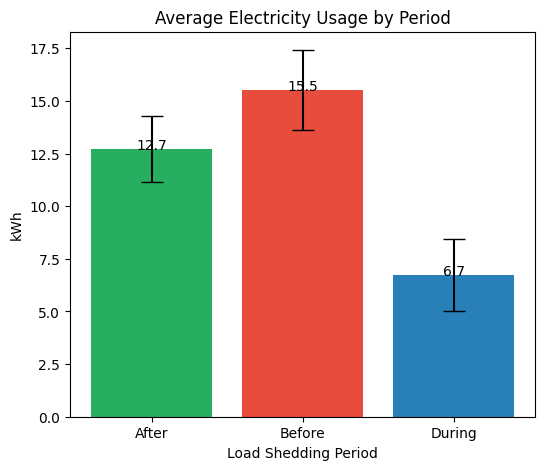

In [11]:
# =====================================================
# 1. Bar Plot – Mean Usage
# =====================================================
means = df.groupby('Load_Shedding_Status')['Electricity_Usage_kWh'].mean()
std_dev = df.groupby('Load_Shedding_Status')['Electricity_Usage_kWh'].std()

plt.figure(figsize=(6,5))
colors = ['#27ae60', '#e74c3c', '#2980b9']  # Green, Red, Blue
bars = plt.bar(means.index, means.values, yerr=std_dev.values, capsize=8, color=colors)

plt.title('Average Electricity Usage by Period')
plt.xlabel('Load Shedding Period')
plt.ylabel('kWh')

for bar, value in zip(bars, means.values):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{value:.1f}', ha='center')

plt.show()

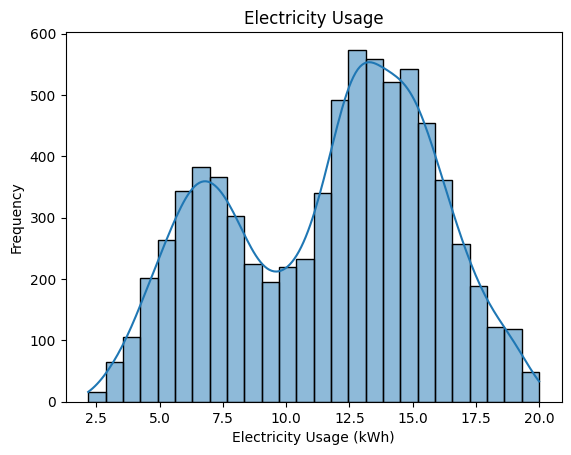

In [12]:
# =====================================================
# 2.Histogram
# =====================================================
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df['Electricity_Usage_kWh'], kde=True)

plt.title("Electricity Usage")
plt.xlabel("Electricity Usage (kWh)")
plt.ylabel("Frequency")

plt.show()

<Figure size 640x480 with 0 Axes>

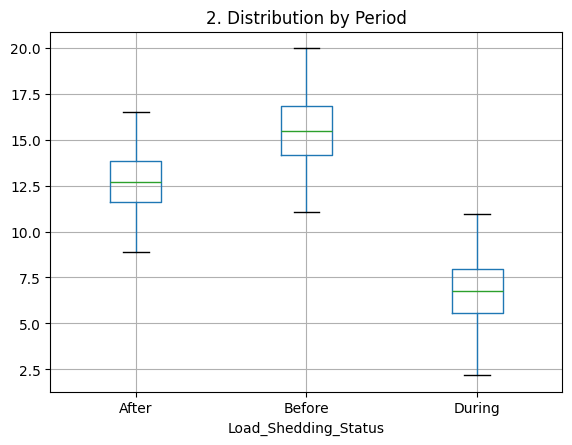

In [13]:
# =====================================================
# 3. Box Plot – Distribution
# =====================================================
plt.figure()
df.boxplot(column='Electricity_Usage_kWh', by='Load_Shedding_Status')
plt.title('2. Distribution by Period')
plt.suptitle('')
plt.show()

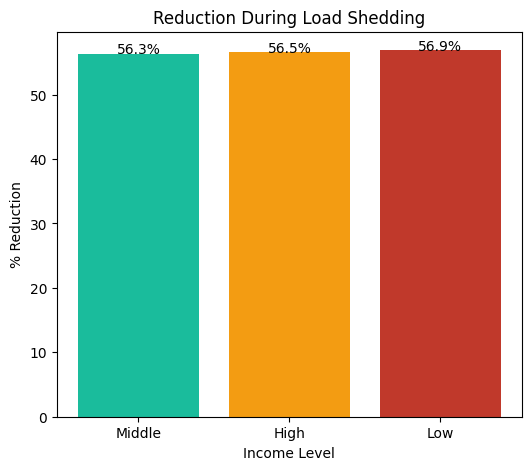

In [14]:
# =====================================================
# 4. Reduction by Income
# =====================================================
income_data = []

for income in df['Income_Level'].unique():
    before = df[(df['Income_Level']==income) & (df['Load_Shedding_Status']=='Before')]['Electricity_Usage_kWh'].mean()
    during = df[(df['Income_Level']==income) & (df['Load_Shedding_Status']=='During')]['Electricity_Usage_kWh'].mean()
    reduction = ((before - during) / before) * 100
    income_data.append({'Income':income, 'Reduction':reduction})

income_df = pd.DataFrame(income_data)

plt.figure(figsize=(6,5))
colors = ['#1abc9c','#f39c12','#c0392b']  # Teal, Orange, Dark Red
bars = plt.bar(income_df['Income'], income_df['Reduction'], color=colors)

plt.title('Reduction During Load Shedding')
plt.xlabel('Income Level')
plt.ylabel('% Reduction')

for bar, value in zip(bars, income_df['Reduction']):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height(), f'{value:.1f}%', ha='center')

plt.show()

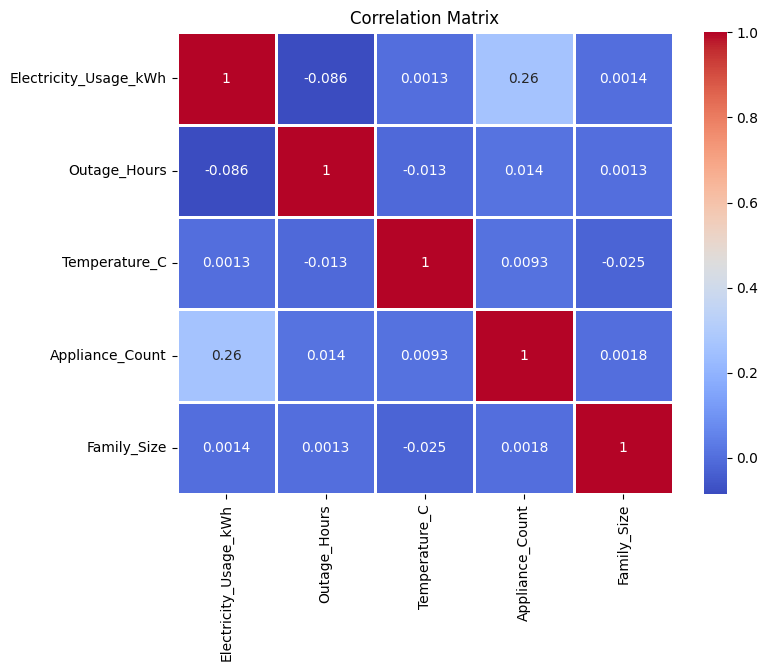

In [15]:
# =====================================================
# 5. Correlation Heatmap
# =====================================================
numeric_cols = ['Electricity_Usage_kWh','Outage_Hours','Temperature_C','Appliance_Count','Family_Size']
corr = df[numeric_cols].corr()

plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap='coolwarm', linewidths=1)

plt.title('Correlation Matrix')
plt.show()

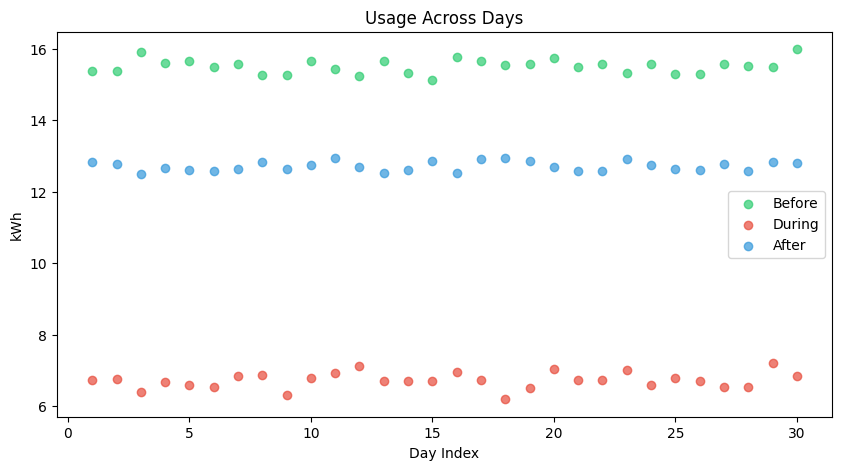

In [16]:
# =====================================================
# 6. Time Series Scatter
# =====================================================
plt.figure(figsize=(10,5))

colors = {
    'Before':'#2ecc71',
    'During':'#e74c3c',
    'After':'#3498db'
}

for period in ['Before','During','After']:
    subset = df[df['Load_Shedding_Status']==period]
    day_avg = subset.groupby('Day_Index')['Electricity_Usage_kWh'].mean()

    plt.scatter(day_avg.index, day_avg.values,
                label=period, color=colors[period], alpha=0.7)

plt.title('Usage Across Days')
plt.xlabel('Day Index')
plt.ylabel('kWh')
plt.legend()

plt.show()

# FINAL SUMMARY

In [17]:
print("\n" + "="*60)
print("FINAL SUMMARY")
print("="*60)
print(f"""
Key Findings:

1. MAIN EFFECT:
   • Load shedding reduces electricity usage by {((before-during)/before*100):.1f}%
   • After shedding ends, usage recovers to {((after/before)*100):.1f}% of normal
   • Differences are statistically significant (p < 0.001)

2. TWO-WAY ANOVA RESULTS:
   • Load Shedding Period: SIGNIFICANT (p = {period_p:.4f})
   • Area Type: {'SIGNIFICANT' if area_p < 0.05 else 'NOT significant'} (p = {area_p:.4f})
   • Interaction (Area × Period): {'SIGNIFICANT' if interaction_p < 0.05 else 'NOT significant'} (p = {interaction_p:.4f})

3. PRACTICAL SIGNIFICANCE:
   • Effect sizes are large (Cohen's d > 1.5)
   • Results are consistent across all subgroups

4. OTHER FACTORS:
   • Appliance count increases usage
   • Longer outages decrease usage
""")
print("="*60)


FINAL SUMMARY

Key Findings:

1. MAIN EFFECT:
   • Load shedding reduces electricity usage by 56.9%
   • After shedding ends, usage recovers to 82.1% of normal
   • Differences are statistically significant (p < 0.001)

2. TWO-WAY ANOVA RESULTS:
   • Load Shedding Period: SIGNIFICANT (p = 0.0000)
   • Area Type: NOT significant (p = 0.3044)
   • Interaction (Area × Period): NOT significant (p = 0.8167)

3. PRACTICAL SIGNIFICANCE:
   • Effect sizes are large (Cohen's d > 1.5)
   • Results are consistent across all subgroups

4. OTHER FACTORS:
   • Appliance count increases usage
   • Longer outages decrease usage

